# Capping and Censoring Outliers (Winsorization)

**Outlier capping** (also known as **censoring** or **Winsorization**) consists of clamping extreme values to predetermined maximum and minimum thresholds, rather than discarding the rows.

Values higher than the upper threshold are set equal to the upper threshold, and values lower than the lower threshold are set equal to the lower threshold.

---

## Learning Objectives
By the end of this notebook, you will be able to:
1. Understand why capping is **preferred over trimming** in production machine learning pipelines.
2. Calculate capping thresholds using the **Gaussian rule**, **IQR rule**, and **percentile boundaries** strictly on the training set.
3. Apply capping using modern, Copy-on-Write safe pandas syntax (`Series.clip()`).
4. Apply the fitted training thresholds to the **test set** safely without data leakage.
5. Inspect the resulting distribution shape and verify that no sample data is lost.

---
## 1. Why Capping is Preferred Over Trimming

| Dimension | Trimming (Removing Outliers) | Capping (Winsorization) |
| :--- | :--- | :--- |
| **Dataset Size** | Decreases (drops observations). | **Preserved 100%** (all rows retained). |
| **Test Set Applicability** | Impractical (cannot drop rows in production). | **Seamless** (extreme test inputs are clipped to learned bounds). |
| **Information Retention** | Discards entire rows (including valid values in other features). | Keeps all other features intact; moderates the extreme feature. |
| **Model Sensitivity** | Protects linear models and neural networks from extreme slopes. | Protects models while keeping full sample size. |

---

### Core ML Best Practice: Preventing Data Leakage
- Compute boundaries ($Q_1, Q_3, IQR, \mu, \sigma$) **exclusively on `X_train`**.
- Apply those exact fixed boundaries to clip both `X_train` and `X_test`. Never recalculate thresholds on test data!

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

# Matplotlib styling
plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['font.size'] = 10

---
## 2. Loading Data & Splitting Train/Test Sets

We use the Breast Cancer dataset from scikit-learn, which contains continuous physiological cell measurements with noticeable outliers in features like `worst smoothness` and `worst texture`.

In [2]:
# Load dataset
cancer = load_breast_cancer(as_frame=True)
data = cancer.frame

print(f"Dataset shape: {data.shape}")
data.head()

Dataset shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
# Separate predictors and target
X = data.drop("target", axis=1)
y = data["target"]

# Split into 70% train and 30% test BEFORE computing any boundaries
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape},  y_test shape:  {y_test.shape}")

X_train shape: (398, 30), y_train shape: (398,)
X_test shape:  (171, 30),  y_test shape:  (171,)


---
## 3. Diagnostic Visualization Helper

Let's build a visualization function with a boxplot and histogram to inspect distributions before and after capping.

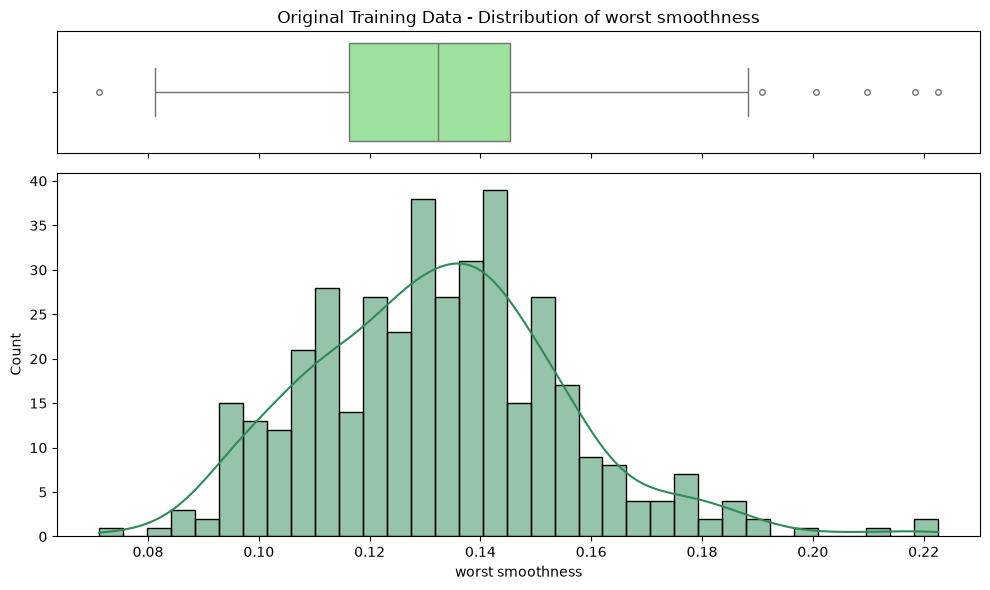

In [4]:
def plot_distribution(df, variable, title=""):
    fig, (ax_box, ax_hist) = plt.subplots(
        2, 1, figsize=(10, 6), sharex=True, gridspec_kw={'height_ratios': [0.25, 0.75]}
    )
    
    # Horizontal boxplot
    sns.boxplot(x=df[variable], ax=ax_box, color='lightgreen', fliersize=4)
    ax_box.set(xlabel='')
    ax_box.set_title(f"{title} - Distribution of {variable}" if title else f"Distribution of {variable}")
    
    # Histogram + KDE
    sns.histplot(df[variable], ax=ax_hist, kde=True, color='seagreen', bins=35)
    ax_hist.set_ylabel("Count")
    
    plt.tight_layout()
    plt.show()

# Inspect 'worst smoothness' before capping
plot_distribution(X_train, "worst smoothness", title="Original Training Data")

---
## 4. Method 1: Capping with the Gaussian / Standard Deviation Rule

If a feature is approximately normally distributed, we calculate:

$$\text{Lower Limit} = \mu - (k \cdot \sigma)$$
$$\text{Upper Limit} = \mu + (k \cdot \sigma)$$

Typically $k = 3.0$ (covering $99.7\%$ of the distribution).

In [5]:
def find_gaussian_limits(df, variable, fold=3.0):
    mean = df[variable].mean()
    std = df[variable].std()
    
    lower_limit = mean - (std * fold)
    upper_limit = mean + (std * fold)
    
    return lower_limit, upper_limit

# Find limits on X_train ONLY
lower_gauss, upper_gauss = find_gaussian_limits(X_train, "worst smoothness", fold=3.0)
print(f"Gaussian Limits for 'worst smoothness' (fold=3.0):")
print(f"  Lower: {lower_gauss:.4f}")
print(f"  Upper: {upper_gauss:.4f}")

Gaussian Limits for 'worst smoothness' (fold=3.0):
  Lower: 0.0636
  Upper: 0.2015


In [6]:
# Create explicit copies to avoid modifying original split
X_train_gauss = X_train.copy()
X_test_gauss = X_test.copy()

print(f"Original X_train min/max: {X_train['worst smoothness'].min():.4f} to {X_train['worst smoothness'].max():.4f}")

# Modern, Copy-on-Write safe capping with .clip()
X_train_gauss["worst smoothness"] = X_train_gauss["worst smoothness"].clip(lower=lower_gauss, upper=upper_gauss)
X_test_gauss["worst smoothness"]  = X_test_gauss["worst smoothness"].clip(lower=lower_gauss, upper=upper_gauss)

print(f"Capped X_train min/max:   {X_train_gauss['worst smoothness'].min():.4f} to {X_train_gauss['worst smoothness'].max():.4f}")
print(f"Capped X_test min/max:    {X_test_gauss['worst smoothness'].min():.4f} to {X_test_gauss['worst smoothness'].max():.4f}")
print(f"Verify row count is 100% preserved: {len(X_train_gauss)} rows")

Original X_train min/max: 0.0712 to 0.2226
Capped X_train min/max:   0.0712 to 0.2015
Capped X_test min/max:    0.0841 to 0.1902
Verify row count is 100% preserved: 398 rows


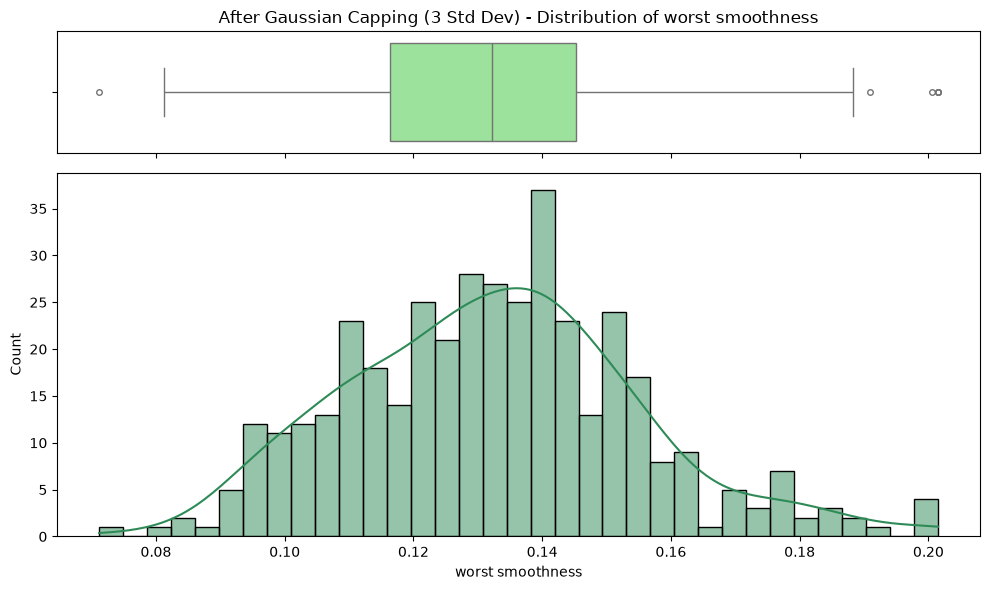

In [7]:
# Visualize after Gaussian capping
plot_distribution(X_train_gauss, "worst smoothness", title="After Gaussian Capping (3 Std Dev)")

Notice how all points beyond the upper limit are now clamped exactly to $0.2017$, eliminating the long tail without dropping any rows!

---
## 5. Method 2: Capping with the IQR Rule (Tukey's Fences)

For skewed variables or variables with non-normal tails, the **IQR method** is preferred:

$$\text{Lower Limit} = Q_1 - (k \cdot \text{IQR})$$
$$\text{Upper Limit} = Q_3 + (k \cdot \text{IQR})$$

IQR Limits (fold=1.5): Lower = 0.0728, Upper = 0.1887


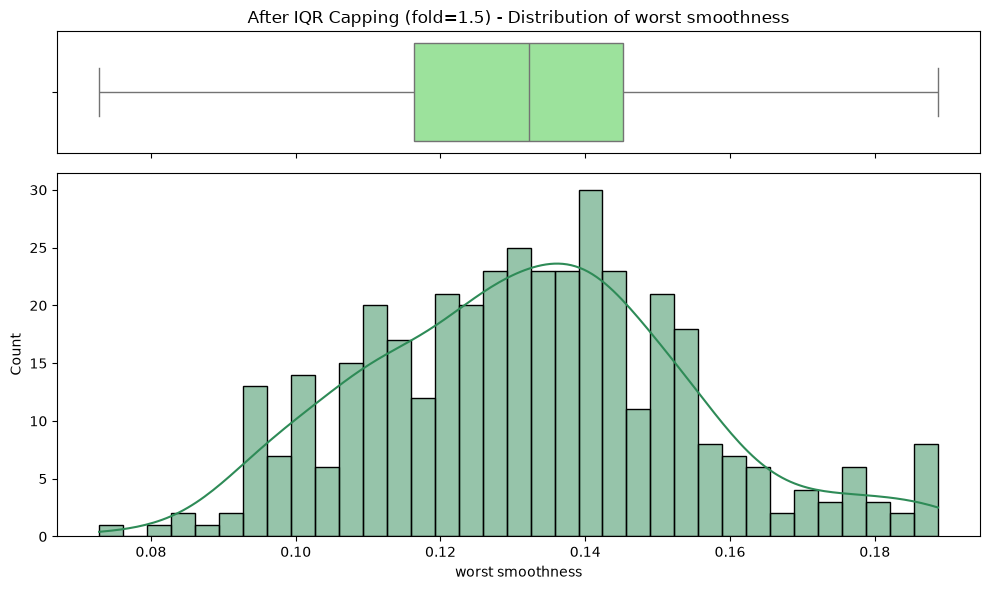

In [8]:
def find_iqr_limits(df, variable, fold=1.5):
    q25 = df[variable].quantile(0.25)
    q75 = df[variable].quantile(0.75)
    iqr = q75 - q25
    
    lower_limit = q25 - (iqr * fold)
    upper_limit = q75 + (iqr * fold)
    
    return lower_limit, upper_limit

# Compute IQR limits on X_train (using standard fold=1.5)
lower_iqr, upper_iqr = find_iqr_limits(X_train, "worst smoothness", fold=1.5)
print(f"IQR Limits (fold=1.5): Lower = {lower_iqr:.4f}, Upper = {upper_iqr:.4f}")

X_train_iqr = X_train.copy()
X_test_iqr = X_test.copy()

# Cap both sets using training boundaries
X_train_iqr["worst smoothness"] = X_train_iqr["worst smoothness"].clip(lower=lower_iqr, upper=upper_iqr)
X_test_iqr["worst smoothness"]  = X_test_iqr["worst smoothness"].clip(lower=lower_iqr, upper=upper_iqr)

plot_distribution(X_train_iqr, "worst smoothness", title="After IQR Capping (fold=1.5)")

---
## 6. Method 3: Capping with Quantiles / Percentiles

We can also cap features at fixed empirical percentiles, such as the $5^{\text{th}}$ and $95^{\text{th}}$ (or $1^{\text{st}}$ and $99^{\text{th}}$) percentiles.

Quantile Limits (5% and 95%): Lower = 0.0961, Upper = 0.1732


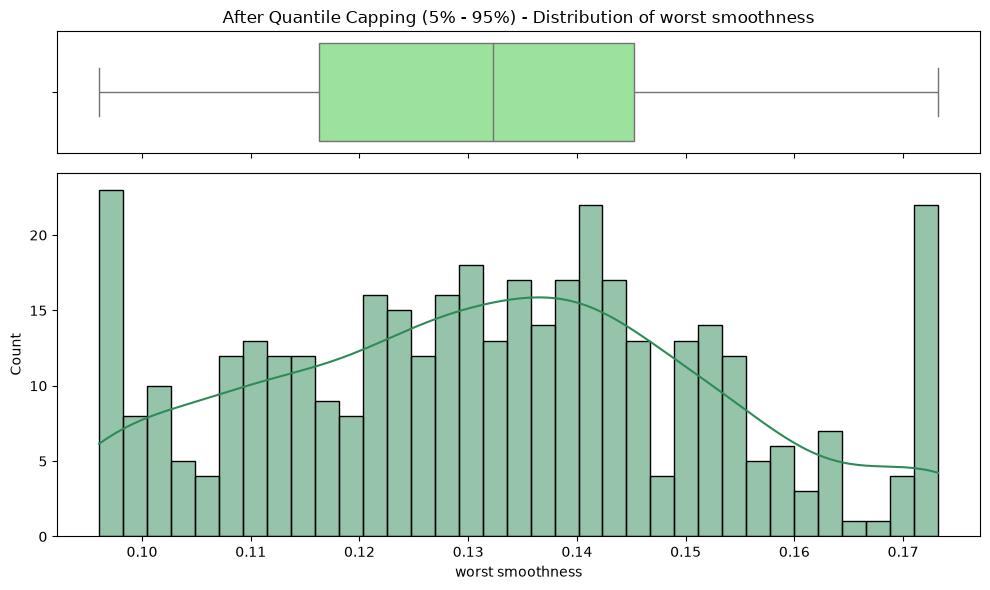

In [9]:
# Calculate 5th and 95th percentiles on X_train
lower_q = X_train["worst smoothness"].quantile(0.05)
upper_q = X_train["worst smoothness"].quantile(0.95)
print(f"Quantile Limits (5% and 95%): Lower = {lower_q:.4f}, Upper = {upper_q:.4f}")

X_train_q = X_train.copy()
X_test_q = X_test.copy()

# Apply capping
X_train_q["worst smoothness"] = X_train_q["worst smoothness"].clip(lower=lower_q, upper=upper_q)
X_test_q["worst smoothness"]  = X_test_q["worst smoothness"].clip(lower=lower_q, upper=upper_q)

plot_distribution(X_train_q, "worst smoothness", title="After Quantile Capping (5% - 95%)")

---
## 7. Summary & Best Practices Checklist

| Technique | When to Use | Key Advantage |
| :--- | :--- | :--- |
| **Gaussian Capping** | Bell-shaped / approximately normal distributions. | Grounded in standard normal probability ($\mu \pm 3\sigma$). |
| **IQR Capping** | Skewed features or unknown distributions. | Robust to extreme outliers; standard Tukey benchmark. |
| **Quantile Capping** | Fixed domain limits (e.g. top 1% capped). | Simple to communicate; guarantees exact boundary percentiles. |

### Golden Rules:
1. **Always assign back explicitly**: Use `df[col] = df[col].clip(lower, upper)` rather than deprecated inplace methods.
2. **Prevent Data Leakage**: Limits must be computed strictly on `X_train`, and the fitted limits applied to `X_test`.
3. **Preserve Dataset Integrity**: Capping leaves row counts intact and allows identical preprocessing on real-time production inference.
